# Testando o custo de preparar um estado quântico de uma imagem 32 x 32

In [2]:
import numpy as np
from PIL import Image

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation


# 1) Carregar imagem 32x32 em escala de cinza
img = Image.open("imagem.png").convert("L").resize((32, 32))
x = np.asarray(img, dtype=float).flatten()

# 2) Normalizar para virar amplitudes
norm = np.linalg.norm(x)
if norm == 0:
    raise ValueError("Imagem toda zerada não pode ser normalizada.")

amplitudes = x / norm

# 3) Conferir tamanho: 32*32 = 1024 = 2^10
n_qubits = int(np.log2(len(amplitudes)))
print("Número de pixels:", len(amplitudes))
print("Número de qubits:", n_qubits)

# 4) Construir circuito de preparação do estado
qc = QuantumCircuit(n_qubits)
prep = StatePreparation(amplitudes)
qc.append(prep, range(n_qubits))

print("\nCircuito abstrato:")
print(qc)
print("Operações abstratas:", qc.count_ops())

# 5) Decompor para portas básicas
qc_decomp = transpile(
    qc,
    basis_gates=["u3", "cx"],
    optimization_level=0
)

print("\nOperações após decomposição:")
print(qc_decomp.count_ops())
print("Profundidade:", qc_decomp.depth())
print("Total de operações:", sum(qc_decomp.count_ops().values()))

Número de pixels: 1024
Número de qubits: 10

Circuito abstrato:
     »
q_0: »
     »
q_1: »
     »
q_2: »
     »
q_3: »
     »
q_4: »
     »
q_5: »
     »
q_6: »
     »
q_7: »
     »
q_8: »
     »
q_9: »
     »
«     ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

# Teste do codigo de teletransporte

Criando estado quântico a ser teletransportado:

In [ ]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator

# Probabilidades desejadas para o estado inicial
p0 = 0.8
p1 = 0.2

alpha = np.sqrt(p0)
beta = np.sqrt(p1)

psi = [alpha, beta] 

print("Estado inicial:")
print(f"|psi> = {alpha:.4f}|0> + {beta:.4f}|1>")
print(f"P(0) = {p0}")
print(f"P(1) = {p1}")

Estado inicial:
|psi> = 0.8944|0> + 0.4472|1>
P(0) = 0.8
P(1) = 0.2


Criando circuito que fará entrelaçamento entre os dois ultimos qubits e irá transferir o primeiro para o último:

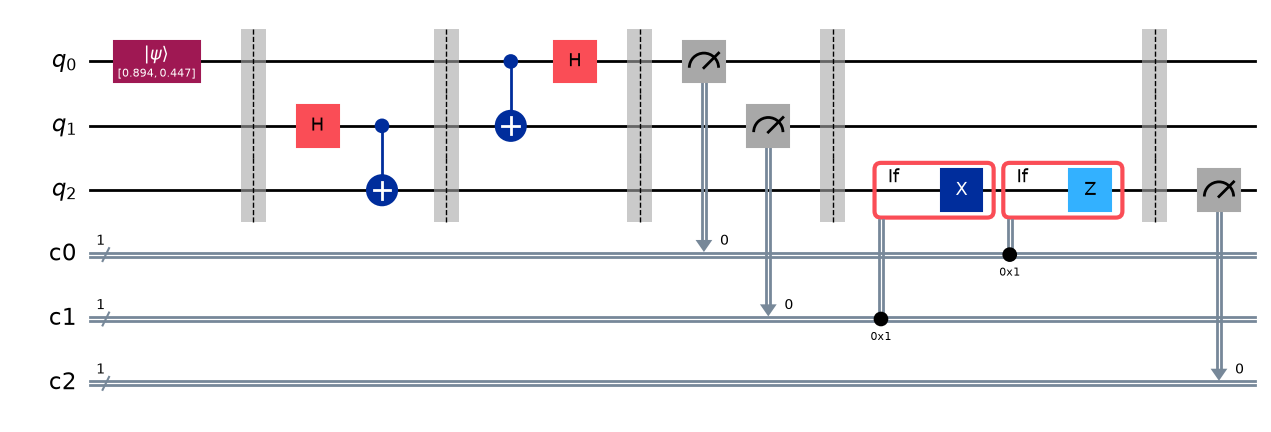

In [26]:
q = QuantumRegister(3, "q")

c0 = ClassicalRegister(1, "c0")
c1 = ClassicalRegister(1, "c1")
c2 = ClassicalRegister(1, "c2")

qc = QuantumCircuit(q, c0, c1, c2)

# q[0] recebe o estado que queremos teleportar
qc.initialize(psi, q[0])
qc.barrier()

# Criando o par de Bell entre q[1] e q[2]
qc.h(q[1])
qc.cx(q[1], q[2])

qc.barrier()

# Etapa da Alice
qc.cx(q[0], q[1])
qc.h(q[0])

qc.barrier()

# Alice mede os dois primeiros qubits
qc.measure(q[0], c0[0])
qc.measure(q[1], c1[0])

qc.barrier()

# Correções condicionais no qubit do Bob, q[2]
with qc.if_test((c1, 1)):
    qc.x(q[2])

with qc.if_test((c0, 1)):
    qc.z(q[2])

qc.barrier()

# Mede o qubit final
qc.measure(q[2], c2[0])

qc.draw("mpl")

Fazendo simulações:

In [24]:
sim = AerSimulator()

shots = 10000
result = sim.run(qc, shots=shots).result()
counts = result.get_counts()

print(counts)

{'110': 493, '101': 509, '001': 1969, '000': 1988, '010': 2097, '111': 500, '011': 1949, '100': 495}


Obtendo qual o terceiro qubit após a medição dos dois primeiros:

In [25]:
final_counts = {"0": 0, "1": 0}

for bitstring, count in counts.items():
    # No Qiskit, a ordem visual dos registradores clássicos pode aparecer separada por espaços.
    # Exemplo: '0 1 0'
    bits = bitstring.replace(" ", "")

    # c2 é o bit da esquerda nessa configuração de registradores
    final_bit = bits[0]

    final_counts[final_bit] += count

print("Contagem do qubit final:")
print(final_counts)

print("Frequências:")
print("P(0) ≈", final_counts["0"] / shots)
print("P(1) ≈", final_counts["1"] / shots)

Contagem do qubit final:
{'0': 8003, '1': 1997}
Frequências:
P(0) ≈ 0.8003
P(1) ≈ 0.1997
